# 02 風圧と隙間

風上・風下の圧力差と室内圧力。VentSim比較例の基礎モデル。

## 到達目標
Q = sign(Δp) a |Δp|^(1/n)。aはm³/(s Pa^(1/n))、nは式中で逆数となる。

## 実行環境
Python 3.10以上とvtsimnx engineが必要です。Colabのlocalhostは手元PCのサーバーを指しません。次の設定セルのAPI URLを到達可能なものに変更します。APIキーは環境変数で渡し、ノートに保存しません。

検証engine commit: `5eeffb2f8012a2fe41bca705450b0dd0a952326d`。入力モデルは実計算確認済ですが、原住宅の年間再現とは範囲が異なります。

## 実行版の使い方
このノートは検証対象のvtsimnx commit 5eeffb2f8012a2fe41bca705450b0dd0a952326d に合わせた代表教材です。上から順に実行します。
Pythonクライアントの導入だけではengineは起動しません。教材17以外は接続可能なengineと、必要に応じてVTSIMNX_API_KEYが必要です。Colabの127.0.0.1は手元PCのengineを指しません。
入力はノート内に含めています。元のDriveパスや測定CSVを別途読む必要はありません。
出力は教材フォルダ内のresults/02/に保存します。詳しい準備は同じフォルダの00_実行ガイド.ipynbを参照してください。


In [1]:
import os, sys, subprocess
# 検証runnerのみ専用環境で導入済みの依存を再利用する。通常はこのセルで導入する。
if os.environ.get("VTSIMNX_TUTORIAL_SKIP_INSTALL") != "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", "pip", "setuptools>=68,<81", "wheel"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
        "vtsimnx @ git+https://github.com/iguchi-lab/vtsimnx@5eeffb2f8012a2fe41bca705450b0dd0a952326d",
        "matplotlib", "japanize-matplotlib"])


In [2]:
import os, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from IPython.display import display
import vtsimnx as vt

# ローカルJupyterでは、ノートブックと同じフォルダを作業フォルダにする。
DATA_DIR = Path(os.environ.get("VTSIMNX_TUTORIAL_DATA", ".")).expanduser().resolve()
BASE_URL = os.environ.get("VTSIMNX_API_URL", "http://127.0.0.1:8000")
API_KEY = os.environ.get("VTSIMNX_API_KEY")
OUTPUT = DATA_DIR / "results" / "02"
OUTPUT.mkdir(parents=True, exist_ok=True)


## 入力を読む
次の辞書はvtsimnxのネイティブ形式です。風量はm³/s、熱量はW、熱容量はJ/Kです。

In [3]:
configs = {'02_wind_gap': {'builder': {},
                 'simulation': {'index': {'start': '2026-01-01T00:00:00',
                                          'end': '2026-01-01T23:00:00',
                                          'length': 24,
                                          'timestep': 3600}},
                 'nodes': [{'key': 'windward',
                            'p': [2.0,
                                  2.2588190451025207,
                                  2.5,
                                  2.7071067811865475,
                                  2.8660254037844384,
                                  2.965925826289068,
                                  3.0,
                                  2.965925826289068,
                                  2.866025403784439,
                                  2.7071067811865475,
                                  2.5,
                                  2.258819045102521,
                                  2.0,
                                  1.7411809548974797,
                                  1.5,
                                  1.2928932188134525,
                                  1.1339745962155616,
                                  1.0340741737109318,
                                  1.0,
                                  1.0340741737109316,
                                  1.1339745962155614,
                                  1.2928932188134523,
                                  1.4999999999999996,
                                  1.7411809548974793],
                            't': 5},
                           {'key': 'leeward', 'p': 0, 't': 5},
                           {'key': 'room', 'p': 0, 't': 20, 'calc_p': True}],
                 'ventilation_branches': [{'key': 'windward->room',
                                           'source': 'windward',
                                           'target': 'room',
                                           'type': 'gap',
                                           'a': 0.01,
                                           'n': 1.5384615384615383},
                                          {'key': 'room->leeward',
                                           'source': 'room',
                                           'target': 'leeward',
                                           'type': 'gap',
                                           'a': 0.01,
                                           'n': 1.5384615384615383}],
                 'thermal_branches': []}}


## 実行と結果の取得
計算ごとの要求JSONを保存し、必要な系列をDataFrameとして取得します。

In [4]:
results = {}
for name, config in configs.items():
    results[name] = vt.run_calc(BASE_URL, config, api_key=API_KEY,
        as_result=True, raise_on_error=True, timeout=1800, request_output_path=OUTPUT / (name + "_request.json"))
    print(name, results[name].artifact_dir)


02_wind_gap artifacts.1794699384533.output.508eb504c0544919a24377f9d2828183


02_wind_gap


,room->leeward,windward->room
time,,
2026-01-01 00:00:00,0.010000,0.010000
2026-01-01 01:00:00,0.010823,0.010823
2026-01-01 02:00:00,0.011561,0.011561
2026-01-01 03:00:00,0.012175,0.012175
2026-01-01 04:00:00,0.012635,0.012635


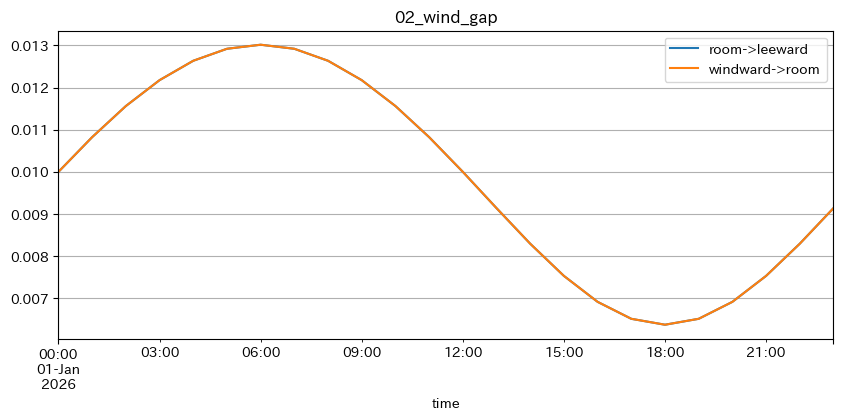

In [5]:
frames = {name: result.get_series_df('vent_flow_rate', raise_on_error=True) for name, result in results.items()}
for name, frame in frames.items():
    print(name)
    display(frame.head())
    frame.to_csv(OUTPUT / (name + "_vent_flow_rate.csv"), encoding="utf-8-sig")
    frame.plot(title=name, figsize=(10, 4), grid=True)


## 確認・発展
風圧の符号を反転し、流れの向きを確認する。

保存された時刻の値は当該ステップ更新後の値です。初期値との比較ではこの差に注意します。

## 原典との対応
- S010 Untitled8.ipynb
- S330 Untitled0.ipynb
- S369 Untitled0.ipynb
- S380 251207_vtsimnx_test.ipynb
- S381 260106_vtsim_vs_ventsim
- S400 260517_vtsim_vs_ventsim
- S405 2607012_vtsim_vs_ventsim

S番号は原典調査時の識別子です。原典の完全な台帳は管理者のDrive整理資料に保管しています。